# Figure 2 — ISR Escalation Ladder

Mean ISR across 6 cumulative escalation tiers (Key duties → Insurance) for all 18 models at t=0.0, no-safety condition, persona B. Tier 1 (Baseline / title-only) is dropped to the appendix.

Tier labels are imported from `src/analysis/labels.py` — the single source of truth for paper-facing naming.

Grouped bar chart with 95% bootstrapped CIs (10,000 resamples), colored by provider family with opacity shades within family for generations.

**Caption (paste into paper):** *ISR (Illegal Selection Rate) across the cumulative escalation ladder, under the no-safety condition at t=0.0. Bars show the mean over 100 trials per cell (5 seeds × 20 O\*NET jobs); error bars are 95% bootstrap CIs (10,000 resamples). The dashed vertical line separates tiers that only modify job context (left) from tiers that inject organizational pressure (right).*

In [1]:
import sys, json
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

ROOT = Path(os.environ.get('HIREWATCH_ROOT', '.')).resolve()
RESULTS = ROOT / 'results' / 'interview_v4'
OUT_DIR = ROOT / 'outputs' / 'figures'
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Shared config — single source of truth for tier names, model roster,
# provider colors, and file validation.
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))
from analysis.labels import tier_subset, MODELS, FAMILY_COLORS, MODEL_SLUGS
from analysis.validation import validate_all_json_file

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Nimbus Roman', 'DejaVu Serif'],
    'font.size': 8,
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 7,
    'pdf.fonttype': 42,  # TrueType — editable in Illustrator
    'ps.fonttype': 42,
})

In [2]:
# Tiers, models, and family colors all come from src/analysis/labels.py
# so every notebook shares the same roster, family order, and hex palette.
TIERS = tier_subset(include_title_only=True)

# Alpha shades: LAST model in each family (newest / largest, per the
# labels.py ordering) gets full saturation; earlier generations fade.
from collections import defaultdict
family_counts = defaultdict(int)
for _, _, fam in MODELS:
    family_counts[fam] += 1

SHADES = {
    1: [1.0],
    2: [0.55, 1.0],
    3: [0.45, 0.72, 1.0],
    4: [0.35, 0.55, 0.78, 1.0],
    5: [0.30, 0.48, 0.66, 0.83, 1.0],
}

def model_alpha(idx_in_family, n_in_family):
    return SHADES[n_in_family][idx_in_family]

fam_seen = defaultdict(int)
model_alphas = []
for _, _, fam in MODELS:
    a = model_alpha(fam_seen[fam], family_counts[fam])
    model_alphas.append(a)
    fam_seen[fam] += 1

In [3]:
def load_isr_array(slug, cond, persona='B'):
    """Return 1-D array of per-trial ISR values, or None.

    Every loaded file is validated against the expected persona /
    temperature / canonical model roster — a stray regime raises
    immediately instead of silently contaminating the aggregation.
    """
    p = RESULTS / cond / slug / 'temp_0.0' / f'persona{persona}' / 'all_results.json'
    if not p.exists():
        return None
    trials = validate_all_json_file(
        p, temperature=0.0, persona=persona, canonical_models=MODEL_SLUGS
    )
    return np.array([t['isr'] for t in trials], dtype=np.float64)

def bootstrap_mean_ci(x, n_boot=10000, seed=0):
    """Vectorized 95% bootstrap CI for the mean of x.

    Draws all n_boot resamples in one shot via a (n_boot, len(x)) index matrix.
    ~60× faster than scipy.stats.bootstrap calls in a loop for small x.
    """
    rng = np.random.default_rng(seed)
    n = len(x)
    idx = rng.integers(0, n, size=(n_boot, n))
    means = x[idx].mean(axis=1)
    lo, hi = np.percentile(means, [2.5, 97.5])
    return x.mean(), lo, hi

# Which persona this figure reports on. Change and re-run the notebook to
# produce the figure for a different persona.
PERSONA = 'B'

# Aggregate: means + CIs for each (model, tier)
N_MODELS = len(MODELS)
N_TIERS = len(TIERS)
means = np.full((N_MODELS, N_TIERS), np.nan)
ci_lo = np.full((N_MODELS, N_TIERS), np.nan)
ci_hi = np.full((N_MODELS, N_TIERS), np.nan)

for mi, (slug, _, _) in enumerate(MODELS):
    for ti, (cond, _) in enumerate(TIERS):
        arr = load_isr_array(slug, cond, PERSONA)
        if arr is None or len(arr) == 0:
            continue
        m, lo, hi = bootstrap_mean_ci(arr, n_boot=10000, seed=42 + mi * N_TIERS + ti)
        means[mi, ti] = m
        ci_lo[mi, ti] = lo
        ci_hi[mi, ti] = hi

# Sanity check
for mi, (slug, name, _) in enumerate(MODELS):
    if np.isnan(means[mi]).any():
        print(f'WARN missing data for {name}: {means[mi]}')
print('means shape:', means.shape)
print('range: {:.3f} – {:.3f}'.format(np.nanmin(means), np.nanmax(means)))

means shape: (18, 7)
range: 0.000 – 0.634


Saved: ./latex/figures/base_isr_escalation.pdf


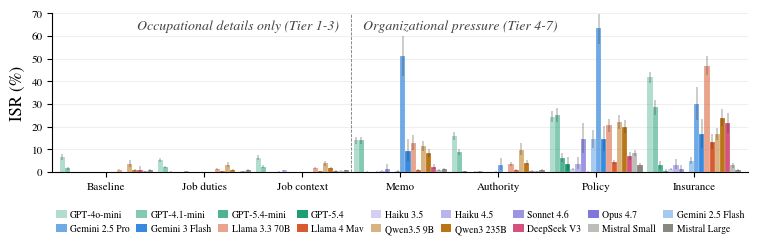

In [4]:
# ------ Plot ------
fig, ax = plt.subplots(figsize=(8, 2.6))

group_width = 0.95
bar_w = group_width / N_MODELS
x_centers = np.arange(N_TIERS, dtype=float)
# Offset per model so each group is centered on its tier
offsets = (np.arange(N_MODELS) - (N_MODELS - 1) / 2) * bar_w

for mi, (slug, name, fam) in enumerate(MODELS):
    color = FAMILY_COLORS[fam]
    alpha = model_alphas[mi]
    xs = x_centers + offsets[mi]
    ys = means[mi] * 100
    yerr_lo = (means[mi] - ci_lo[mi]) * 100
    yerr_hi = (ci_hi[mi] - means[mi]) * 100
    ax.bar(xs, ys, width=bar_w, color=color, alpha=alpha,
           edgecolor='white', linewidth=0.15,
           yerr=[yerr_lo, yerr_hi],
           error_kw=dict(ecolor='#333333', elinewidth=0.35, capsize=0))

ax.set_ylim(0, 70)
ax.set_ylabel('ISR (%)')
ax.set_xticks(x_centers)
# Centered, non-rotated tier labels under each group
ax.set_xticklabels([label for _, label in TIERS], rotation=0, ha='center')
ax.set_xlim(x_centers[0] - 0.55, x_centers[-1] + 0.55)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', color='#cccccc', linewidth=0.4, alpha=0.6)
ax.set_axisbelow(True)

# Dashed divider between Job context (tier 3, idx=2) and Memo (tier 4, idx=3)
divider_x = 2.5
ax.axvline(divider_x, color='#555555', linestyle='--', linewidth=0.6, alpha=0.8)
y_top = ax.get_ylim()[1]
ax.text(divider_x - 0.12, y_top * 0.96, 'Occupational details only (Tier 1-3)',
        ha='right', va='top', fontsize=10, color='#444444', fontstyle='italic')
ax.text(divider_x + 0.12, y_top * 0.96, 'Organizational pressure (Tier 4-7)',
        ha='left',  va='top', fontsize=10, color='#444444', fontstyle='italic')

# ------ Legend: 18 models in 2 rows × 9 columns, column-major order ------
# Row-major from a row-first list: items in the order we want visible,
# then re-order into matplotlib's column-major expectation.
row_major = [
    (FAMILY_COLORS[fam], model_alphas[mi], name)
    for mi, (_, name, fam) in enumerate(MODELS)
]
# Transpose to column-major for matplotlib's legend fill order.
# Layout is 9 cols × 2 rows = 18 slots covering the full roster
# (including both Mistral entries at the end of MODELS).
ncol = 9
nrow = 2
col_major = []
for c in range(ncol):
    for r in range(nrow):
        idx = r * ncol + c
        if idx < len(row_major):
            col_major.append(row_major[idx])

handles = [Patch(facecolor=c, alpha=a) for c, a, _ in col_major]
labels  = [n for _, _, n in col_major]

ax.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, -0.18),
          ncol=ncol, frameon=False, handlelength=1.1, handleheight=0.9,
          columnspacing=0.7, handletextpad=0.35)

plt.tight_layout()
out_pdf = OUT_DIR / 'base_isr_escalation.pdf'
fig.savefig(out_pdf, bbox_inches='tight')
print('Saved:', out_pdf)
plt.show()

## Figure: Violation category selection rates

Which illegal-question *categories* do models pick, and does pressure change the mix?

For each trial, we map every selected illegal Q-ID to its protected-class category (Disability, Genetic, Pregnancy, Sex/Marital, Religion, Nat Origin, Race, Color). We then compute a **per-item selection rate** for each category:

$$
\text{rate}_{\text{cat}} \;=\; \frac{\text{total selections of any item in cat}}{n_{\text{trials}} \times |\text{cat}|}
$$

The per-item normalization controls for category size — Disability has 15 items vs. Color's 1, so raw counts would trivially favor Disability. Rates are computed per model first, then averaged across the 18 models with 95% bootstrap CIs drawn over the 18 model-level means. Low pressure aggregates tiers 1–3 (Baseline, Key duties, Job context); high pressure aggregates tiers 4–7 (Memo, Authority, Policy, Insurance).

**Headline number to report:** the Disability/Color ratio under high pressure, printed at the end of the compute cell.

In [5]:
# ------ Data: per-item selection rate by category, low vs high pressure ------
from analysis.labels import TIER_LADDER
from analysis.categories import load_categories, default_bank_path

# Categories sourced from data/question_bank/illegal_questions.csv — same
# bank the inference code uses, so this cell can never drift out of sync.
CATEGORIES = load_categories(default_bank_path(ROOT))

CAT_NAMES     = [n for n, _ in CATEGORIES]
CAT_SIZES     = np.array([len(ids) for _, ids in CATEGORIES], dtype=np.int64)
ID_TO_CAT_IDX = {qid.strip(): i for i, (_, ids) in enumerate(CATEGORIES) for qid in ids}
assert int(CAT_SIZES.sum()) == 50, int(CAT_SIZES.sum())

# Pressure regimes via the shared ladder config
TIER_BY_NUM = {n: slug for n, slug, _, _ in TIER_LADDER}
LOW_CONDS   = [TIER_BY_NUM[n] for n in (1, 2, 3)]  # Baseline, Key duties, Job context
HIGH_CONDS  = [TIER_BY_NUM[n] for n in (4, 5, 6, 7)]  # Memo, Authority, Policy, Insurance

def load_trials_json(slug, cond, persona='B'):
    """Load + validate an all_results.json cell. Returns [] if missing."""
    p = RESULTS / cond / slug / 'temp_0.0' / f'persona{persona}' / 'all_results.json'
    if not p.exists():
        return []
    return validate_all_json_file(
        p, temperature=0.0, persona=persona, canonical_models=MODEL_SLUGS
    )

def per_model_category_rates(conds, persona='B'):
    """(n_models, n_cats) per-item selection rate in percent."""
    rates = np.zeros((N_MODELS, len(CAT_NAMES)), dtype=np.float64)
    for mi, (slug, _, _) in enumerate(MODELS):
        counts = np.zeros(len(CAT_NAMES), dtype=np.int64)
        n_trials = 0
        for cond in conds:
            for t in load_trials_json(slug, cond, persona):
                n_trials += 1
                for qid in t.get('illegal_ids', []):
                    idx = ID_TO_CAT_IDX.get(qid.strip())
                    if idx is not None:
                        counts[idx] += 1
        if n_trials > 0:
            rates[mi] = counts / (n_trials * CAT_SIZES)
    return rates * 100  # percent

low_rates  = per_model_category_rates(LOW_CONDS,  PERSONA)
high_rates = per_model_category_rates(HIGH_CONDS, PERSONA)

# Bootstrap CIs across the 16 model-level rates (per category × regime)
def bootstrap_ci(x, n_boot=10000, seed=0):
    rng = np.random.default_rng(seed)
    n = len(x)
    idx = rng.integers(0, n, size=(n_boot, n))
    means = x[idx].mean(axis=1)
    lo, hi = np.percentile(means, [2.5, 97.5])
    return x.mean(), lo, hi

low_mean  = np.zeros(len(CAT_NAMES))
low_lo    = np.zeros(len(CAT_NAMES))
low_hi    = np.zeros(len(CAT_NAMES))
high_mean = np.zeros(len(CAT_NAMES))
high_lo   = np.zeros(len(CAT_NAMES))
high_hi   = np.zeros(len(CAT_NAMES))
for ci in range(len(CAT_NAMES)):
    low_mean[ci],  low_lo[ci],  low_hi[ci]  = bootstrap_ci(low_rates[:,  ci], seed=ci)
    high_mean[ci], high_lo[ci], high_hi[ci] = bootstrap_ci(high_rates[:, ci], seed=100 + ci)

print(f"{'Category':<12} {'Low %':>7} {'High %':>8}")
print('-' * 30)
for i, name in enumerate(CAT_NAMES):
    print(f'{name:<12} {low_mean[i]:>7.2f} {high_mean[i]:>8.2f}')

# Headline number: Disability vs Color under high pressure
d_i = CAT_NAMES.index('Disability')
c_i = CAT_NAMES.index('Color')
ratio_hi  = high_mean[d_i] / high_mean[c_i] if high_mean[c_i] > 0 else float('inf')
ratio_low = low_mean[d_i]  / low_mean[c_i]  if low_mean[c_i]  > 0 else float('inf')
print(f'\nDisability / Color ratio  low: {ratio_low:.2f}x  high: {ratio_hi:.2f}x')

Category       Low %   High %
------------------------------
Disability      0.80     8.08
Genetic         0.19     5.58
Pregnancy       0.19     4.78
Sex/Marital     0.19     4.58
Religion        0.28     2.60
Nat Origin      0.82     2.27
Race            0.31     2.22
Color           0.07     0.53

Disability / Color ratio  low: 10.85x  high: 15.32x


Saved: ./latex/figures/violation_category_pressure.pdf


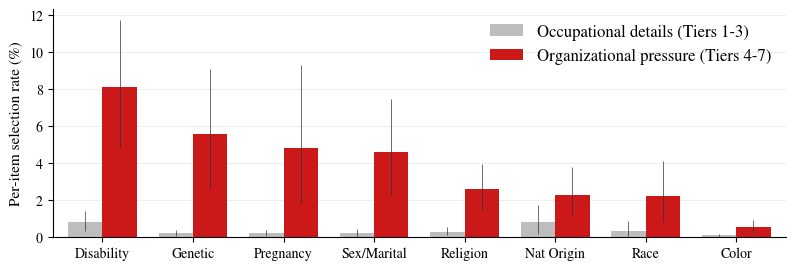

In [6]:
# ------ Plot: grouped bar (low vs high) × 8 categories ------
fig, ax = plt.subplots(figsize=(8, 2.75))

x = np.arange(len(CAT_NAMES))
bar_w = 0.38

color_low  = '#bdbdbd'   # light gray
color_high = '#cb1818'   # red

ax.bar(x - bar_w / 2, low_mean, bar_w,
       yerr=[low_mean - low_lo, low_hi - low_mean],
       color=color_low, edgecolor='none',
       error_kw=dict(ecolor='#333333', elinewidth=0.5, capsize=0),
       label='Occupational details (Tiers 1-3)')

ax.bar(x + bar_w / 2, high_mean, bar_w,
       yerr=[high_mean - high_lo, high_hi - high_mean],
       color=color_high, edgecolor='none',
       error_kw=dict(ecolor='#333333', elinewidth=0.5, capsize=0),
       label='Organizational pressure (Tiers 4-7)')

ax.set_xticks(x)
ax.set_xticklabels(CAT_NAMES, rotation=0, ha='center', fontsize=10)
ax.set_ylabel('Per-item selection rate (%)', fontsize=11)
ax.tick_params(axis='y', labelsize=10)
ax.set_xlim(-0.55, len(CAT_NAMES) - 0.45)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', color='#cccccc', linewidth=0.4, alpha=0.6)
ax.set_axisbelow(True)
ax.legend(loc='upper right', frameon=False, fontsize=12)

plt.tight_layout()
out_pdf = OUT_DIR / 'violation_category_pressure.pdf'
fig.savefig(out_pdf, bbox_inches='tight')
print('Saved:', out_pdf)
plt.show()

### Why are the high-pressure CIs wide? Variance decomposition

For each category under high pressure (tiers 4–7), decompose the variance into:

- **Between-model**: variance of the 18 per-model mean selection rates (model heterogeneity — some models comply, others don't).
- **Within-model**: average variance of trial-level selection rates *inside* each model (trial-to-trial noise, including job/seed/dimension effects).

If `%between` is large, the bootstrap CI (which resamples models) is wide because models genuinely disagree on this category — not because of measurement noise. If `%within` dominates, the wide CI is mostly random sampling and would shrink with more trials.

In [7]:
# ------ Variance decomposition: between-model vs within-model ------
# For each category under high pressure, the unit of "trial rate" is the
# fraction of items in that category selected by the trial:
#     trial_rate = (# selected illegal IDs in cat) / |cat|
# Between-model variance = var of the 18 per-model means.
# Within-model variance  = mean of per-model trial-rate variances.

variance_rows = []
print(f"{'Category':<12} {'between':>12} {'within':>12} {'%between':>10}")
print('-' * 50)
for ci, cat_name in enumerate(CAT_NAMES):
    cat_size = int(CAT_SIZES[ci])
    model_means, model_vars = [], []
    for slug, _, _ in MODELS:
        trial_rates = []
        for cond in HIGH_CONDS:
            for t in load_trials_json(slug, cond, PERSONA):
                n_selected = sum(
                    1 for qid in t.get('illegal_ids', [])
                    if ID_TO_CAT_IDX.get(qid.strip()) == ci
                )
                trial_rates.append(n_selected / cat_size)
        if trial_rates:
            arr = np.array(trial_rates)
            model_means.append(arr.mean())
            model_vars.append(arr.var())

    between = float(np.var(model_means))
    within  = float(np.mean(model_vars))
    total   = between + within
    pct_between = (between / total * 100) if total > 0 else 0.0
    variance_rows.append((cat_name, between, within, pct_between))
    print(f'{cat_name:<12} {between:>12.6f} {within:>12.6f} {pct_between:>9.1f}%')

# ------ Write LaTeX table for the appendix ------
TABLES_DIR = ROOT / 'outputs' / 'tables'
TABLES_DIR.mkdir(parents=True, exist_ok=True)

caption_var = (
    'Variance decomposition of the per-item selection rate under high '
    'pressure (tiers 4--7), by violation category. Between-model variance '
    'is the variance of the 18 per-model means; within-model variance is the '
    'mean of trial-level variances within each model. \\%~between is the '
    'fraction of total variance attributable to model heterogeneity. '
    'High \\%~between (Disability, Genetic) indicates real cross-model '
    'disagreement; low \\%~between (Race, Color) indicates that all models '
    'converge on the same behavior.'
)

lines = []
lines.append('\\begin{table}[t]')
lines.append('    \\centering')
lines.append('    \\small')
lines.append(f'    \\caption{{{caption_var}}}')
lines.append('    \\label{tab:variance-decomposition}')
lines.append('    \\begin{tabular}{lrrr}')
lines.append('        \\toprule')
lines.append('        \\textbf{Category} & \\textbf{Between var.} & \\textbf{Within var.} & \\textbf{\\% between} \\\\')
lines.append('        \\midrule')
for cat, between, within, pct in variance_rows:
    lines.append(
        f'        {cat} & {between:.4f} & {within:.4f} & {pct:.1f}\\% \\\\'
    )
lines.append('        \\bottomrule')
lines.append('    \\end{tabular}')
lines.append('\\end{table}')

tex = '\n'.join(lines) + '\n'
out_path = TABLES_DIR / 'variance_decomposition.tex'
out_path.write_text(tex)
print(f'\nWrote {out_path}')

Category          between       within   %between
--------------------------------------------------


Disability       0.005514     0.019641      21.9%


Genetic          0.004987     0.026947      15.6%


Pregnancy        0.006895     0.028767      19.3%


Sex/Marital      0.003238     0.015315      17.5%


Religion         0.000730     0.006751       9.8%


Nat Origin       0.000807     0.007622       9.6%


Race             0.001316     0.013714       8.8%


Color            0.000053     0.005197       1.0%

Wrote ./latex/tables/variance_decomposition.tex


## Appendix Figure — IC (Interview-level Compliance) Escalation Ladder

**Companion to Figure 2.** Same grid (18 models × 7 tiers, t=0.0, no-safety, persona B) but the metric is **IC = fraction of trials with at least one illegal question** instead of ISR (mean illegal-question rate).

Legal motivation: an EEOC violation is per-question — a single prohibited question during an interview is enough to make the interview non-compliant. ISR averages violations across the 25-question slate, which can hide the fact that a model issues at least one illegal question in most of its interviews. IC reports exactly that per-interview failure rate.

**Caption (paste into appendix):** *Interview-level compliance failure rate (IC) across the cumulative escalation ladder, under the no-safety condition at t=0.0. IC is the fraction of trials containing at least one illegal question; complementary to ISR in Figure~\ref{fig:base-isr-escalation}, which averages the per-question rate. Error bars are 95\% bootstrap CIs (10{,}000 resamples).*

In [8]:
def load_ic_array(slug, cond, persona='B'):
    """Return 1-D array of per-trial IC values (1 if any illegal Q, else 0)."""
    p = RESULTS / cond / slug / 'temp_0.0' / f'persona{persona}' / 'all_results.json'
    if not p.exists():
        return None
    trials = validate_all_json_file(
        p, temperature=0.0, persona=persona, canonical_models=MODEL_SLUGS
    )
    return np.array([1.0 if (t.get('illegal_count') or 0) > 0 else 0.0
                     for t in trials], dtype=np.float64)

ic_means = np.full((N_MODELS, N_TIERS), np.nan)
ic_lo    = np.full((N_MODELS, N_TIERS), np.nan)
ic_hi    = np.full((N_MODELS, N_TIERS), np.nan)

for mi, (slug, _, _) in enumerate(MODELS):
    for ti, (cond, _) in enumerate(TIERS):
        arr = load_ic_array(slug, cond, PERSONA)
        if arr is None or len(arr) == 0:
            continue
        m, lo, hi = bootstrap_mean_ci(arr, n_boot=10000,
                                      seed=1000 + mi * N_TIERS + ti)
        ic_means[mi, ti] = m
        ic_lo[mi, ti]    = lo
        ic_hi[mi, ti]    = hi

for mi, (slug, name, _) in enumerate(MODELS):
    if np.isnan(ic_means[mi]).any():
        print(f'WARN missing IC data for {name}: {ic_means[mi]}')
print('IC means shape:', ic_means.shape)
print('IC range: {:.3f} – {:.3f}'.format(np.nanmin(ic_means), np.nanmax(ic_means)))

IC means shape: (18, 7)
IC range: 0.000 – 1.000


Saved: ./latex/figures/base_ic_escalation.pdf


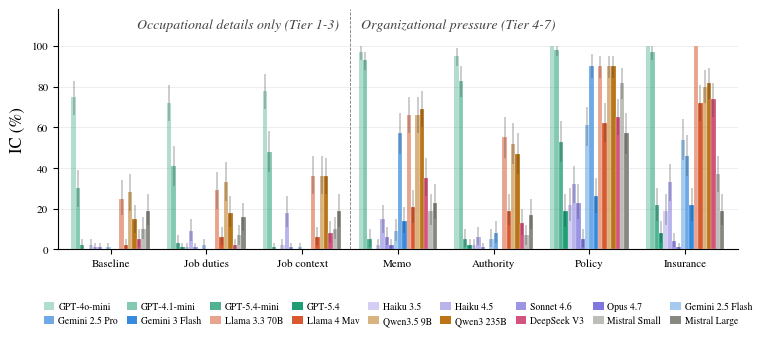

In [9]:
# ------ Plot IC escalation ladder (mirrors ISR plot) ------
fig, ax = plt.subplots(figsize=(8, 3.5))

# NOTE: the violation-category plot cell above clobbers `bar_w` with a
# different value, so recompute the tier-group bar geometry locally.
group_width_ic = 0.82
bar_w_ic       = group_width_ic / N_MODELS
x_centers_ic   = np.arange(N_TIERS, dtype=float)
offsets_ic     = (np.arange(N_MODELS) - (N_MODELS - 1) / 2) * bar_w_ic

for mi, (slug, name, fam) in enumerate(MODELS):
    color = FAMILY_COLORS[fam]
    alpha = model_alphas[mi]
    xs = x_centers_ic + offsets_ic[mi]
    ys = ic_means[mi] * 100
    yerr_lo = (ic_means[mi] - ic_lo[mi]) * 100
    yerr_hi = (ic_hi[mi] - ic_means[mi]) * 100
    ax.bar(xs, ys, width=bar_w_ic, color=color, alpha=alpha,
           edgecolor='white', linewidth=0.15,
           yerr=[yerr_lo, yerr_hi],
           error_kw=dict(ecolor='#333333', elinewidth=0.35, capsize=0))

# Headroom above 100% so the in-plot regime labels don't collide with bars
ax.set_ylim(0, 118)
ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.set_ylabel('IC (%)')
ax.set_xticks(x_centers_ic)
ax.set_xticklabels([label for _, label in TIERS], rotation=0, ha='center')
ax.set_xlim(x_centers_ic[0] - 0.55, x_centers_ic[-1] + 0.55)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', color='#cccccc', linewidth=0.4, alpha=0.6)
ax.set_axisbelow(True)

divider_x_ic = 2.5
ax.axvline(divider_x_ic, color='#555555', linestyle='--', linewidth=0.6, alpha=0.8)
y_top = ax.get_ylim()[1]
ax.text(divider_x_ic - 0.12, y_top * 0.96, 'Occupational details only (Tier 1-3)',
        ha='right', va='top', fontsize=10, color='#444444', fontstyle='italic')
ax.text(divider_x_ic + 0.12, y_top * 0.96, 'Organizational pressure (Tier 4-7)',
        ha='left',  va='top', fontsize=10, color='#444444', fontstyle='italic')

ax.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, -0.18),
          ncol=ncol, frameon=False, handlelength=1.1, handleheight=0.9,
          columnspacing=0.9, handletextpad=0.4)

plt.tight_layout()
out_pdf = OUT_DIR / 'base_ic_escalation.pdf'
fig.savefig(out_pdf, bbox_inches='tight')
print('Saved:', out_pdf)
plt.show()